In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
from sklearn.datasets import load_diabetes, fetch_california_housing
from sklearn.datasets import load_breast_cancer, load_wine, load_iris

datasets = [
    load_diabetes(),
    fetch_california_housing(),
    load_breast_cancer(),
    load_wine(),
    load_iris()
]

for i, data in enumerate(datasets, 1):
    print(f"Dataset {i}: {data.data.shape}")

Dataset 1: (442, 10)
Dataset 2: (20640, 8)
Dataset 3: (569, 30)
Dataset 4: (178, 13)
Dataset 5: (150, 4)


In [ ]:
data_list = []

for data in datasets:
    X = data.data[:, :2]
    y = data.target

    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    X = np.c_[np.ones(X.shape[0]), X]

    data_list.append((X, y))

print("All 5 datasets are ready.")

All 5 datasets are ready.


In [ ]:
def batch_gradient_descent(X, y, lr=0.01, epochs=1000):
    m, n = X.shape
    theta = np.zeros(n)
    cost_history = []

    for _ in range(epochs):
        predictions = X @ theta
        error = predictions - y
        gradients = (X.T @ error) / m
        theta -= lr * gradients
        cost = np.sum(error ** 2) / (2 * m)
        cost_history.append(cost)

    return theta, cost_history

In [ ]:
def stochastic_gradient_descent(X, y, lr=0.01, epochs=1000):
    m, n = X.shape
    theta = np.zeros(n)
    cost_history = []

    for _ in range(epochs):
        for i in np.random.permutation(m):
            prediction = X[i] @ theta
            error = prediction - y[i]
            theta -= lr * X[i] * error

        predictions = X @ theta
        cost = np.sum((predictions - y) ** 2) / (2 * m)
        cost_history.append(cost)

    return theta, cost_history

In [ ]:
def mini_batch_gradient_descent(X, y, lr=0.01, epochs=1000, batch_size=32):
    m, n = X.shape
    theta = np.zeros(n)
    cost_history = []

    for _ in range(epochs):
        indices = np.random.permutation(m)

        for start in range(0, m, batch_size):
            batch = indices[start:start + batch_size]
            X_batch = X[batch]
            y_batch = y[batch]

            predictions = X_batch @ theta
            error = predictions - y_batch
            gradients = (X_batch.T @ error) / len(batch)
            theta -= lr * gradients

        predictions = X @ theta
        cost = np.sum((predictions - y) ** 2) / (2 * m)
        cost_history.append(cost)

    return theta, cost_history

In [ ]:
results = []

for i, (X, y) in enumerate(data_list, 1):
    theta_b, cost_b = batch_gradient_descent(X, y, epochs=100)
    theta_s, cost_s = stochastic_gradient_descent(X, y, epochs=100)
    theta_m, cost_m = mini_batch_gradient_descent(X, y, epochs=100)

    results.append({
        "Dataset": i,
        "Batch Final Cost": cost_b[-1],
        "Stochastic Final Cost": cost_s[-1],
        "Mini-Batch Final Cost": cost_m[-1]
    })

pd.DataFrame(results)

,Dataset,Batch Final Cost,Stochastic Final Cost,Mini-Batch Final Cost
0,1,4455.658569,2867.382171,2859.947754
1,2,0.671433,0.336187,0.326881
2,3,0.083695,0.050500,0.050416
3,4,0.276585,0.200594,0.200264
4,5,0.187392,0.091371,0.091377


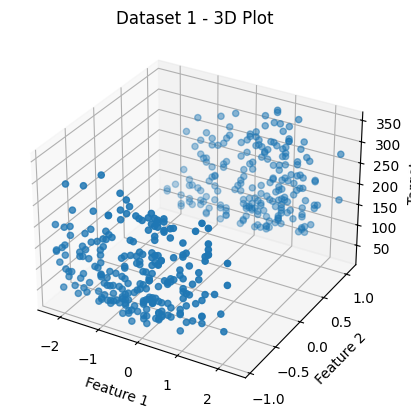

In [ ]:
X, y = data_list[0]

theta = results[0]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X[:, 1], X[:, 2], y)

ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_zlabel("Target")
ax.set_title("Dataset 1 - 3D Plot")

plt.show()

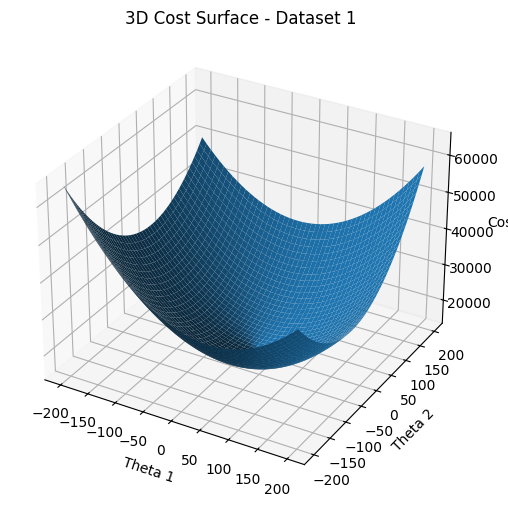

In [ ]:
X, y = data_list[0]

t1 = np.linspace(-200, 200, 50)
t2 = np.linspace(-200, 200, 50)

T1, T2 = np.meshgrid(t1, t2)
J = np.zeros(T1.shape)

for i in range(T1.shape[0]):
    for j in range(T1.shape[1]):
        pred = X[:, 0] * 0 + X[:, 1] * T1[i, j] + X[:, 2] * T2[i, j]
        J[i, j] = np.mean((pred - y) ** 2) / 2

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(T1, T2, J)

ax.set_xlabel("Theta 1")
ax.set_ylabel("Theta 2")
ax.set_zlabel("Cost")
ax.set_title("3D Cost Surface - Dataset 1")

plt.show()

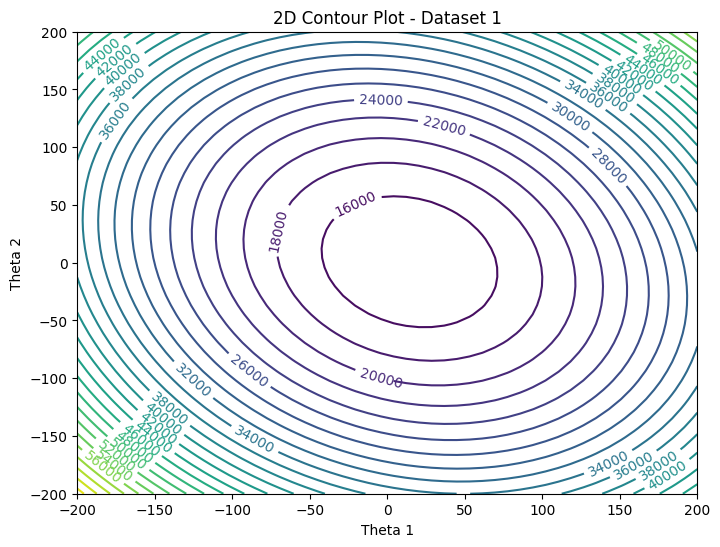

In [ ]:
plt.figure(figsize=(8, 6))

contour = plt.contour(T1, T2, J, levels=30)
plt.clabel(contour)

plt.xlabel("Theta 1")
plt.ylabel("Theta 2")
plt.title("2D Contour Plot - Dataset 1")

plt.show()

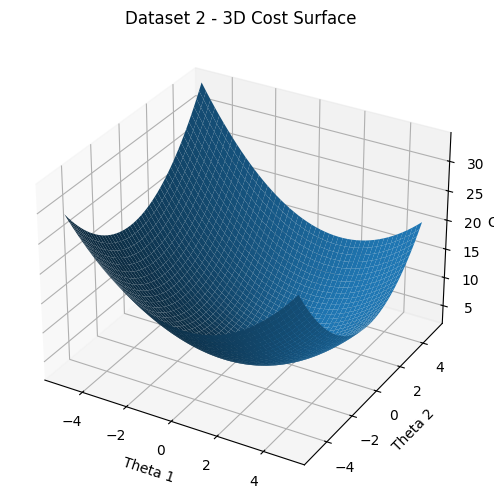

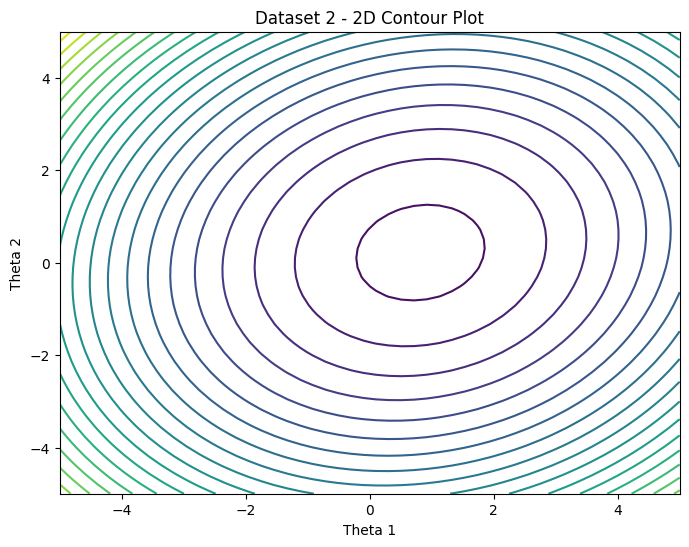

In [ ]:
X, y = data_list[1]

t1 = np.linspace(-5, 5, 50)
t2 = np.linspace(-5, 5, 50)
T1, T2 = np.meshgrid(t1, t2)
J = np.zeros(T1.shape)

for i in range(50):
    for j in range(50):
        pred = X[:, 1] * T1[i, j] + X[:, 2] * T2[i, j]
        J[i, j] = np.mean((pred - y) ** 2) / 2

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T1, T2, J)
ax.set_xlabel("Theta 1")
ax.set_ylabel("Theta 2")
ax.set_zlabel("Cost")
ax.set_title("Dataset 2 - 3D Cost Surface")
plt.show()

plt.figure(figsize=(8, 6))
plt.contour(T1, T2, J, levels=30)
plt.xlabel("Theta 1")
plt.ylabel("Theta 2")
plt.title("Dataset 2 - 2D Contour Plot")
plt.show()

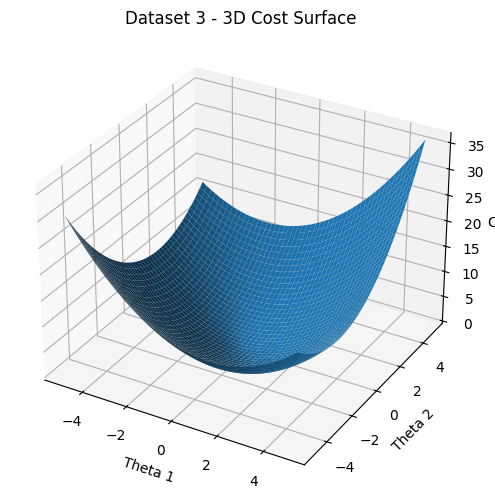

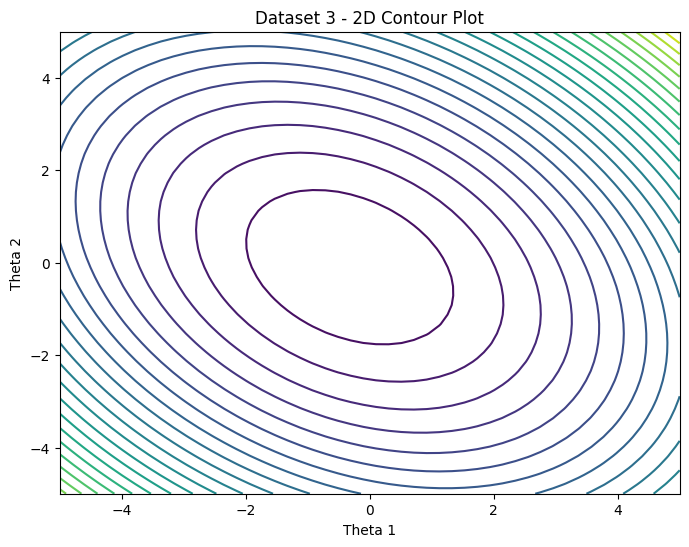

In [ ]:
X, y = data_list[2]

t1 = np.linspace(-5, 5, 50)
t2 = np.linspace(-5, 5, 50)
T1, T2 = np.meshgrid(t1, t2)
J = np.zeros(T1.shape)

for i in range(50):
    for j in range(50):
        pred = X[:, 1] * T1[i, j] + X[:, 2] * T2[i, j]
        J[i, j] = np.mean((pred - y) ** 2) / 2

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T1, T2, J)
ax.set_xlabel("Theta 1")
ax.set_ylabel("Theta 2")
ax.set_zlabel("Cost")
ax.set_title("Dataset 3 - 3D Cost Surface")
plt.show()

plt.figure(figsize=(8, 6))
plt.contour(T1, T2, J, levels=30)
plt.xlabel("Theta 1")
plt.ylabel("Theta 2")
plt.title("Dataset 3 - 2D Contour Plot")
plt.show()

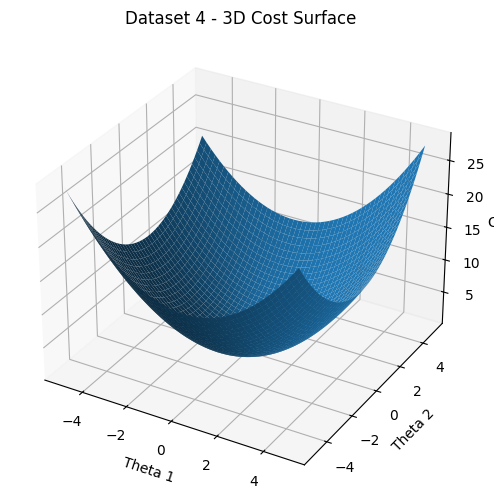

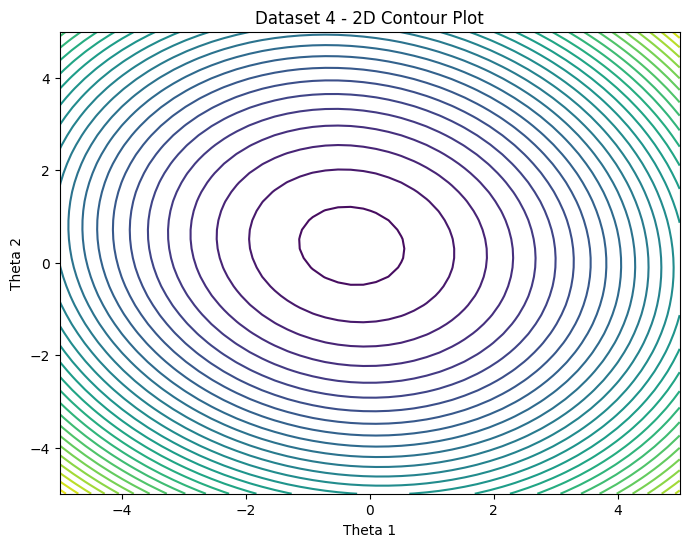

In [ ]:
X, y = data_list[3]

t1 = np.linspace(-5, 5, 50)
t2 = np.linspace(-5, 5, 50)
T1, T2 = np.meshgrid(t1, t2)
J = np.zeros(T1.shape)

for i in range(50):
    for j in range(50):
        pred = X[:, 1] * T1[i, j] + X[:, 2] * T2[i, j]
        J[i, j] = np.mean((pred - y) ** 2) / 2

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T1, T2, J)
ax.set_xlabel("Theta 1")
ax.set_ylabel("Theta 2")
ax.set_zlabel("Cost")
ax.set_title("Dataset 4 - 3D Cost Surface")
plt.show()

plt.figure(figsize=(8, 6))
plt.contour(T1, T2, J, levels=30)
plt.xlabel("Theta 1")
plt.ylabel("Theta 2")
plt.title("Dataset 4 - 2D Contour Plot")
plt.show()

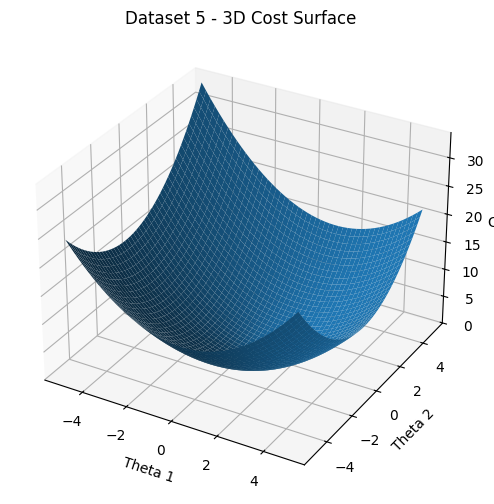

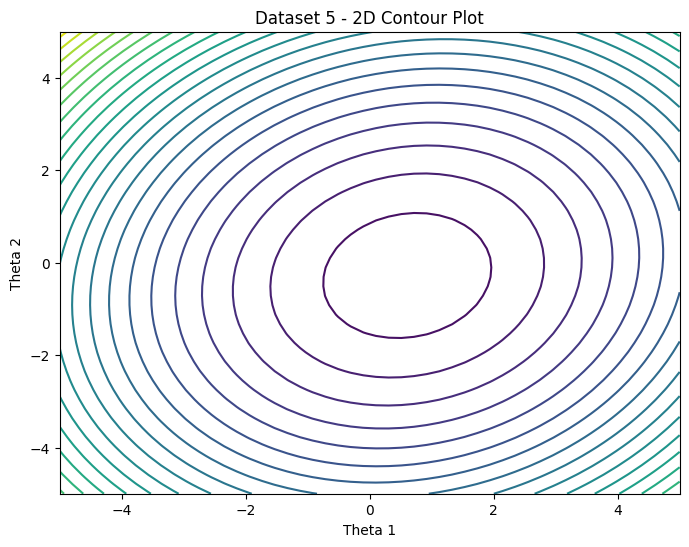

In [ ]:
X, y = data_list[4]

t1 = np.linspace(-5, 5, 50)
t2 = np.linspace(-5, 5, 50)
T1, T2 = np.meshgrid(t1, t2)
J = np.zeros(T1.shape)

for i in range(50):
    for j in range(50):
        pred = X[:, 1] * T1[i, j] + X[:, 2] * T2[i, j]
        J[i, j] = np.mean((pred - y) ** 2) / 2

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T1, T2, J)
ax.set_xlabel("Theta 1")
ax.set_ylabel("Theta 2")
ax.set_zlabel("Cost")
ax.set_title("Dataset 5 - 3D Cost Surface")
plt.show()

plt.figure(figsize=(8, 6))
plt.contour(T1, T2, J, levels=30)
plt.xlabel("Theta 1")
plt.ylabel("Theta 2")
plt.title("Dataset 5 - 2D Contour Plot")
plt.show()
